# Fit for linear bias $b_1$ and derive $b_\phi$ for DESI-like LRG and ELG mocks based on AbacusSummit base sims

In [1]:
import os
from astropy.io import fits
import numpy as np

Path to catalogs on `idark`.

In [2]:
file_path='/lustre/work/jiaxiyu/bphi'
file_prefix='AbacusSummit_base'
cosmo=['c000','c004']
phase=['ph000','ph001','ph002','ph003','ph004']
file_suffix='HOD.fits'
file_name=[[os.path.join(file_path,file_prefix+'_'+c+'_'+ph+'_'+file_suffix) for ph in phase] for c in cosmo]

In [3]:
print(file_name[0][0])

/lustre/work/jiaxiyu/bphi/AbacusSummit_base_c000_ph000_HOD.fits


Read and separate mock galaxies into the `LRG` sample and `ELG` sample.

In [4]:
with fits.open(file_name[0][0]) as hdul:
    hdul.info()
    hdr=hdul[1].header
    data=hdul[1].data
    tr = data['TRACER']
    # Separate `LRG` and `ELG`
    is_LRG = (tr == 'LRG')
    is_ELG = (tr == 'ELG')
    # Tracer properties we keep
    cols = ['x','y','z','vx','vy','vz','halo_id','Central']
    # Copy before we close the fits file
    data = np.array(data, copy=False)
    LRG = data[is_LRG][cols].copy()
    ELG = data[is_ELG][cols].copy()
print(LRG.shape, ELG.shape)

Filename: /lustre/work/jiaxiyu/bphi/AbacusSummit_base_c000_ph000_HOD.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1                1 BinTableHDU     38   13340232R x 15C   [E, E, E, E, E, E, E, E, E, E, E, E, K, D, 3A]   
(4404925,) (8935307,)


In [5]:
LRG

array([(-999.494 ,  999.67596, -666.68207 ,  213.8461 ,  234.79034 ,  7.8701837e+02,          283001000, 1.),
       (-997.8451, -998.6797 , -535.21173 , -162.96053,  469.35355 ,  6.9262147e-01,          395000001, 1.),
       (-999.5038,  999.50006,  -36.872208,   11.31778, -247.3252  , -4.1110867e+02,          818001000, 1.),
       ...,
       (-999.6033,  978.2913 , -899.8817  ,   69.32568,   12.010346,  1.5507344e+02, 170016810084001000, 0.),
       (1000.0895,  997.5027 , -961.4134  ,   80.77087,  159.44885 ,  8.3153619e+02, 170016980032000000, 0.),
       ( 999.94  ,  997.8516 , -961.34015 ,  356.46005, -212.60574 ,  3.3559351e+02, 170016980032000000, 0.)],
      dtype={'names': ['x', 'y', 'z', 'vx', 'vy', 'vz', 'halo_id', 'Central'], 'formats': ['>f4', '>f4', '>f4', '>f4', '>f4', '>f4', '>i8', '>f8'], 'offsets': [0, 4, 8, 12, 16, 20, 48, 56], 'itemsize': 67})

Construct overdensity fields.

In [6]:
import MAS_library as MASL

In [7]:
# galaxy positions
LRG_pos = np.array((LRG['x'],LRG['y'],LRG['z'])).T
ELG_pos = np.array((ELG['x'],ELG['y'],ELG['z'])).T
print(LRG_pos.min())
print(LRG_pos.max())

-1000.55133
1000.4722


In [8]:
# grid construction parameters
Ngrid    = 256 # Grid resolution
BoxSize = 2000.0 # AbacusSummit box size in Mpc/h
MAS     = 'TSC'  # Mass-assigment scheme
verbose = True   # Verbosity

In [9]:
# galaxy count fields
LRG_ng = np.zeros((Ngrid,Ngrid,Ngrid), dtype=np.float32)
ELG_ng = np.zeros_like(LRG_ng)

shift=1000.
# galaxy assignment
MASL.MA(LRG_pos+shift, LRG_ng, BoxSize, MAS, verbose=verbose)
MASL.MA(ELG_pos+shift, ELG_ng, BoxSize, MAS, verbose=verbose)

# galaxy density fields
LRG_delta = LRG_ng/np.mean(LRG_ng,dtype=np.float64)-1.
ELG_delta = ELG_ng/np.mean(ELG_ng,dtype=np.float64)-1.


Using TSC mass assignment scheme
Time taken = 0.393 seconds


Using TSC mass assignment scheme
Time taken = 0.722 seconds



Visual inspection at the field level.

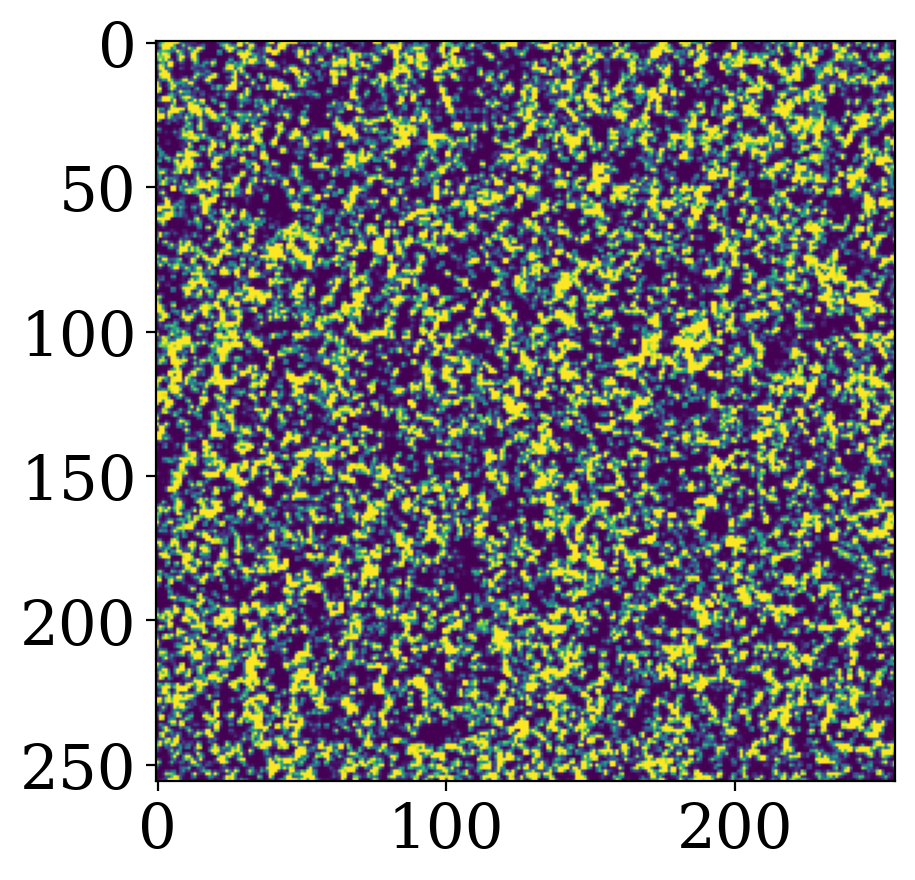

In [10]:
import matplotlib
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.sans-serif": "Computer Modern",
    "font.size": 22})

fig,ax=plt.subplots()
ax.imshow(LRG_delta[0,:,:],vmin=-1.,vmax=1.0)

Compute power spectra.

In [11]:
import Pk_library as PKL

In [12]:
threads=32
axis=0

# compute power spectra
LRG_Pk = PKL.Pk(LRG_delta, BoxSize, axis, MAS, threads, verbose)
ELG_Pk = PKL.Pk(ELG_delta, BoxSize, axis, MAS, threads, verbose)

# 3D P(k)
k       = LRG_Pk.k3D
LRG_Pk0     = LRG_Pk.Pk[:,0] #monopole
ELG_Pk0     = ELG_Pk.Pk[:,0] #monopole
Nmodes  = LRG_Pk.Nmodes3D


Computing power spectrum of the field...
Time to complete loop = 1.46
Time taken = 1.58 seconds

Computing power spectrum of the field...
Time to complete loop = 1.46
Time taken = 1.53 seconds


In [13]:
LRG_nbar=LRG_ng.sum()/(BoxSize**3)
ELG_nbar=ELG_ng.sum()/(BoxSize**3)

LRG_Pshot=(1./LRG_nbar)*np.ones_like(LRG_Pk0)
ELG_Pshot=(1./ELG_nbar)*np.ones_like(ELG_Pk0)

Visual inspection at the power spectrum level.

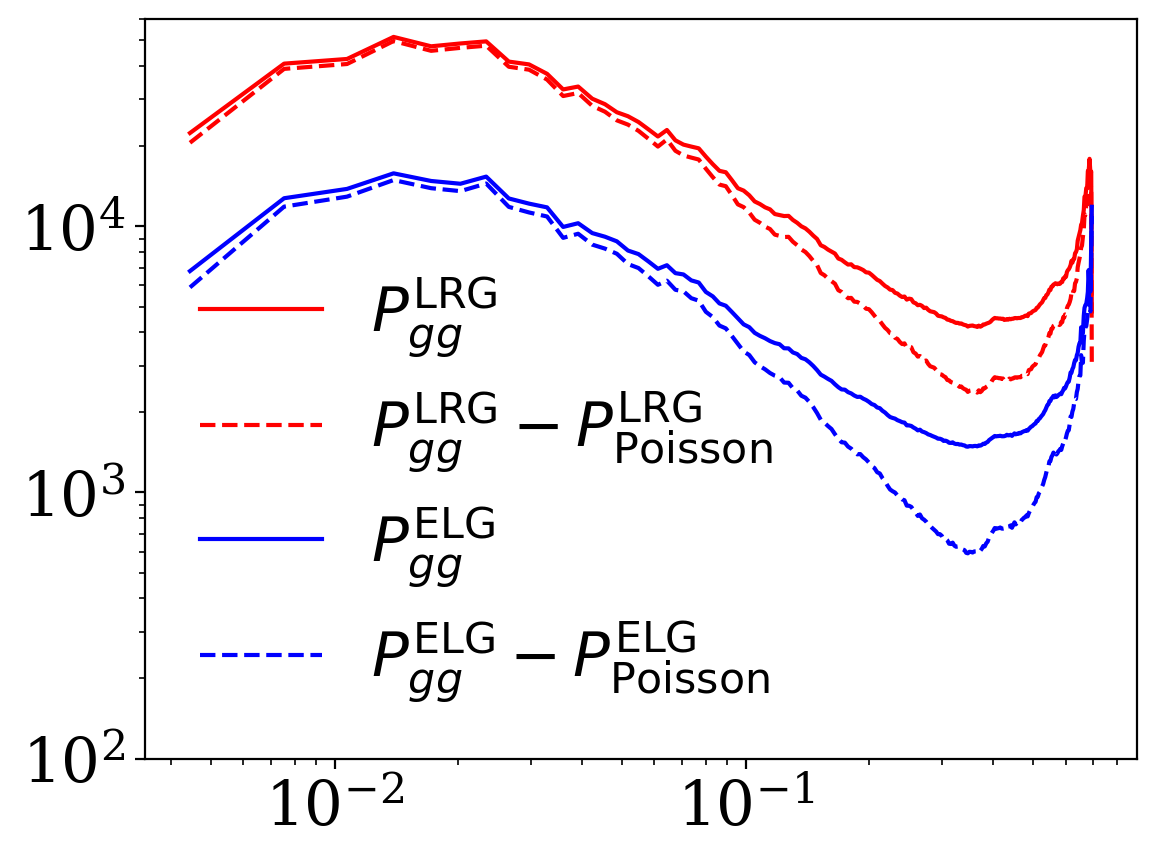

In [14]:
fig,ax=plt.subplots()
ax.loglog(k,LRG_Pk0,c='r',label=r'$P^{\rm LRG}_{gg}$')
ax.loglog(k,LRG_Pk0-LRG_Pshot,c='r',ls='--',label=r'$P^{\rm LRG}_{gg}-P^{\rm LRG}_{\rm Poisson}$')
ax.loglog(k,ELG_Pk0,c='b',label=r'$P^{\rm ELG}_{gg}$')
ax.loglog(k,ELG_Pk0-ELG_Pshot,c='b',ls='--',label=r'$P^{\rm ELG}_{gg}-P^{\rm ELG}_{\rm Poisson}$')
ax.set_ylim(1E2,6E4)
ax.legend(frameon=False)

Set up `camb` and compute the linear matter power spectrum.

In [15]:
import camb
from camb import model, initialpower

print('Using CAMB %s installed at %s' % (camb.__version__, os.path.dirname(camb.__file__)))

Using CAMB 1.5.9 installed at /home/n2minh/.conda/envs/py310forge/lib/python3.10/site-packages/camb


In [16]:
# Setup camb parameters to follow AbacusSummit base cosmology (`c000`)
z_snap=1.1

cosmo_pars = {
        "h":         0.6736,
        "H0":        67.36,
        "omega_b":   0.02237,
        "omega_cdm": 0.1200,
        "A_s":       2.0830e-9,
        #"A_s":       1.7949e-9,
        "n_s":       0.9649,
        "alpha_s":   0.0,
        "tau":       0.0544,
        "Omega_k":   0.0,
        "w_0":       -1.0,
        "w_a":       0.0,
        "N_ur":      2.0328,
        "m_nu1":     0.06,
        "m_nu2":     0.0,
        "m_nu3":     0.0,
        "k_p":       0.05,
        "YHe":       0.245421,
        "Tcmb":      2.7255
}
camb_pars = camb.set_params(H0=cosmo_pars["H0"], ombh2=cosmo_pars["omega_b"], omch2=cosmo_pars["omega_cdm"],\
                            mnu=cosmo_pars["m_nu1"]+cosmo_pars["m_nu2"]+cosmo_pars["m_nu3"], omk=cosmo_pars["Omega_k"],\
                            tau=cosmo_pars["tau"],\
                            As=cosmo_pars["A_s"], ns=cosmo_pars["n_s"],\
                            halofit_version='mead')
# Note non-linear corrections couples to smaller scales than you want
camb_pars.set_matter_power(redshifts=[z_snap,], kmax=2.0)

# Linear spectra
results = camb.get_results(camb_pars)
kmax=10.
zmax=2.0
Pkint = camb.get_matter_power_interpolator(
    camb_pars,
    nonlinear=False,
    hubble_units=True,
    k_hunit=True,
    kmax=kmax,
    zmax=zmax,
)
Pklin=Pkint.P(z_snap,k)

In [17]:
LRG_b1sqr=(LRG_Pk0-LRG_Pshot)/Pklin
LRG_b1=np.mean(np.sqrt(LRG_b1sqr)[k<0.06])
ELG_b1sqr=(ELG_Pk0-ELG_Pshot)/Pklin
ELG_b1=np.mean(np.sqrt(ELG_b1sqr)[k<0.06])

LRG_bphi=2*1.686*(LRG_b1-1.)
ELG_bphi=2*1.686*(ELG_b1-1.)

print("Linear bias for LRGs:")
print("b1=",LRG_b1)
print("Linear bias for ELGs:")
print(r"b1=",ELG_b1)

print("NG linear bias for LRGs:")
print("bphi=",LRG_bphi)
print("NG linear bias for ELGs:")
print(r"bphi=",ELG_bphi)

Linear bias for LRGs:
b1= 2.4108028588460684
Linear bias for ELGs:
b1= 1.3226982945831223
NG linear bias for LRGs:
bphi= 4.757227240028943
NG linear bias for ELGs:
bphi= 1.0881386493342882


Visual inspection at the power spectrum level.

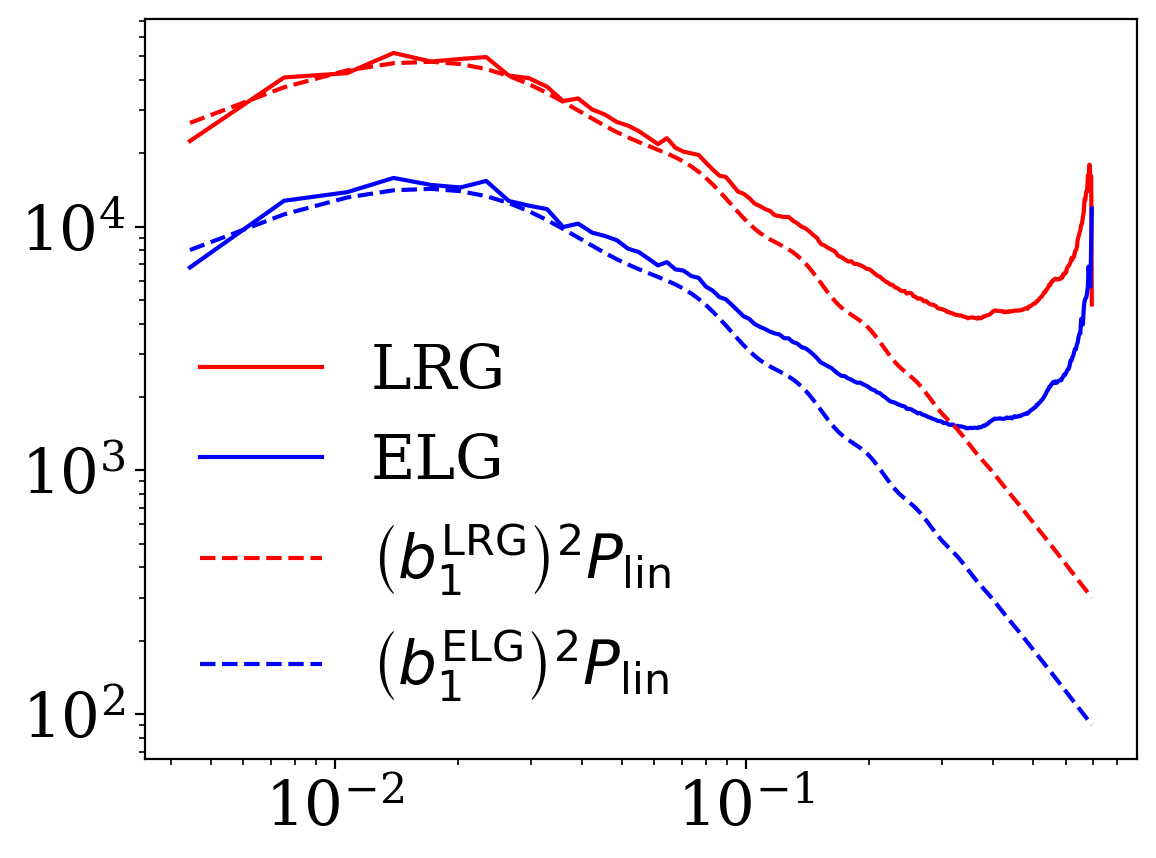

In [18]:
fig,ax=plt.subplots()
ax.loglog(k,LRG_Pk0,c='r',label='LRG')
ax.loglog(k,ELG_Pk0,c='b',label='ELG')
ax.loglog(k,(LRG_b1**2)*Pklin,c='r',ls='--',label=r'$\left(b^{\rm LRG}_1\right)^2P_{\rm lin}$')
ax.loglog(k,(ELG_b1**2)*Pklin,c='b',ls='--',label=r'$\left(b^{\rm ELG}_1\right)^2P_{\rm lin}$')
ax.legend(frameon=False)